# EDA – Finaler Jobmarkt für MeritMe

**Autor:** Tobias Neumann

> **KI-Nutzung:** Entstanden mit Claude (Anthropic) als Coding-Agent und Sparringspartner – für Code-Entwürfe,
> Datenprüfungen und die Diskussion der Methodik. Fachliche Entscheidungen (Ringe, Filter, Schwellen) und die
> Bewertung der Ergebnisse liegen beim Autor. Alle Zahlen stammen aus den Ausgaben dieses Notebooks.

Ziel: ein fester, abgegrenzter Jobmarkt für die Zwillingstests (Ziel 1). Ergebnis ist eine
Parquet-Datei mit den IDs aller Jobs und CVs, ihrer Rolle im Test und den Gründen für ihre Auswahl.

| Baustein | Umfang |
|---|---|
| Jobs | 20 Stellen aus Ring A |
| Bewerberliste | 60 CVs: 20 aus A (Kern), 20 aus B (Rand), 20 aus C (Außen) |
| Zwillings-Quellen | 120 weitere CVs: 70 A + 30 B (Haupttest), 20 C (Kontrolle) |

**Bewerberliste und Zwillings-Quellen sind getrennte CVs**: Die Liste ist die feste, unabhängige Konkurrenz, in die jeder Zwilling eingereiht wird. Stünde das Original eines Zwillings selbst in der Liste, würde der Zwilling gegen eine Fast-Kopie antreten.

**Prinzip:** Ausgestochen wird über das `Primary Keyword` von Djinni. Innerhalb davon filtern wir
nur nach Keyword-Listen und ziehen dann zufällig. Kein Score von MeritMe oder TF-IDF entscheidet,
wer in den Markt kommt. Hintergrund und Herleitung: `eda_keksausstecher.ipynb`.

![Auswahlpipeline des Jobmarkts](../docs/img/Djinni%20ESCO%20Jobmarket%20Dataset%20Pipeline-2026-10-20-170212.png)

## 1. Setup & Konfiguration

Alles, was man ändern kann, steht in dieser Zelle: Ringe, Größen, Schwellen.
Jeder Ring ist eine **ESCO-Berufsfamilie**. Das Djinni-Keyword ist nur der Ausstecher.

In [1]:
import re
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sys.path.append(str(Path("../scripts").resolve()))
from esco_extractor import EscoExtractor, EscoxConfig

CV_PATH = Path("../data/raw/djinni/cv_profiles_en.parquet")
JOB_PATH = Path("../data/raw/djinni/job_postings_en.parquet")
ESCO_DIR = Path("../data/raw/esco")
OUT_DIR = Path("../data/processed")

SEED = 42
N_JOBS = 20
N_LIST = 20                                  # pro Ring in der Bewerberliste
N_TWINS = {"A": 70, "B": 30, "C": 20}        # A+B = Haupttest, C = Kontrolle
MIN_WORDS = 20
MIN_HITS = 5                                 # Mindestanzahl gefundener Keywords


'''
Why A: Unser Fachgebiet: als Data Scientists können wir DE-Profile und Zwillinge beurteilen. ESCO beschreibt Data Engineering vergleichsweise konkret (SQL, ETL, Data Warehouse, BI).
Why B: Nah, aber andere Kernaufgabe: baut Anwendungen statt Datenpipelines. Teilt mit Data Engineering die Sprache Python. Ein typischer Quereinstiegsweg.
Why C: Noch IT und schreibt auch Code, aber die Kernaufgabe (Qualitätssicherung) liegt weit weg von Data Engineering.
'''

RINGS = {
    "A": {
        "name": "Data Engineering",
        "djinni_keyword": "Data Engineer",
        "esco_occupations": ["data engineer", "database developer", "database integrator", "data warehouse designer"],
    },
    "B": {
        "name": "Softwareentwicklung",
        "djinni_keyword": "Python",
        "esco_occupations": ["software developer", "software analyst", "ICT application developer"],
    },
    "C": {
        "name": "Softwaretest",
        "djinni_keyword": "QA Automation",
        "esco_occupations": ["software tester", "ICT test analyst", "ICT system tester", "ICT integration tester"],
    },
}

# Jobs aus A müssen die Rolle im Titel nennen
JOB_TITLE_A = r"data engineer|etl|big ?data|dwh|data warehouse|data platform|data architect|bi engineer|bi developer|database"
JOB_TITLE_EXCLUDE = r"trainer|teacher|mentor|course|recruit" # Lehr- und Recruiting-Stellen

# TF-IDF-Sicht: aus den Top-Begriffen der Ring-Jobs fliegen Wörter ohne eigene technische Bedeutung
# (Rollen, Seniorität, allgemeine Begriffe). Alles andere wird automatisch übernommen (Abschnitt 4).
TOP_TERMS = 30
GENERIC_WORDS = ["data", "big", "engineer", "engineering", "developer", "software", "senior", "experience", "business",
                 "solutions", "sources", "end", "stack", "framework", "frameworks", "tools", "api", "apis", "test",
                 "testing", "tests", "qa", "aqa", "quality", "assurance", "automated", "execute", "execution", "plans",
                 "methodologies", "scripts", "cases", "manual", "machine", "learning", "ai", "databases", "processing",
                 "transformation", "analytics", "apache"]

# ESCO-Skills, deren Namen oder Synonyme im Freitext falsch treffen
STOPLIST = {
    "statistics": "Synonym „big data“",
    "Scratch (computer programming)": "trifft „from scratch“",
    "Visual Basic": "Synonym „.NET“",
    "SPARK": "in ESCO ein Java-Framework, nicht Apache Spark",
    "Source (digital game creation systems)": "trifft „source“",
    "computer programming": "Synonym „io“",
}
# Für die TF-IDF-Sicht vergleichen wir die Jobs eines Rings mit allen anderen IT-Jobs.
# IT-Jobs erkennen wir am Primary Keyword, nicht über ESCO-Skills, damit diese Sicht unabhängig von ESCO bleibt.
IT_KEYWORDS = ["JavaScript", "Node.js", "PHP", "Ruby", "Java", ".NET", "Python", "Golang", "Scala", "Rust",
               "C++", "iOS", "Android", "Flutter", "Unity", "Data Science", "Data Engineer", "Data Analyst",
               "SQL", "QA", "QA Automation", "DevOps", "Sysadmin", "Security", "Salesforce"]

In [2]:


# Farb-/Stilkonstanten (wie in den anderen EDA-Notebooks)
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
ORANGE = "#eb6834"
OTHER_GREY = "#c3c2b7"
RING_COLORS = {"A": "#104281", "B": "#2a78d6", "C": "#86b6ef"}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

In [3]:
pd.DataFrame(RINGS).T[["name", "djinni_keyword"]]

,name,djinni_keyword
A,Data Engineering,Data Engineer
B,Softwareentwicklung,Python
C,Softwaretest,QA Automation


## 2. Daten laden

Djinni-CVs und -Jobs sowie die ESCO-Tabellen (Skills, Berufe, Beruf↔Skill).

In [4]:
cv = pd.read_parquet(CV_PATH)
jobs = pd.read_parquet(JOB_PATH)

skills = pd.read_csv(ESCO_DIR / "skills_en.csv").fillna("").drop_duplicates("conceptUri")  # 21 Zeilen doppelt
occupations = pd.read_csv(ESCO_DIR / "occupations_en.csv").fillna("")
occ_skills = pd.read_csv(ESCO_DIR / "occupationSkillRelations_en.csv")
digital = set(pd.read_csv(ESCO_DIR / "digitalSkillsCollection_en.csv")["conceptUri"])

print(f"CVs: {len(cv):,} | Jobs: {len(jobs):,}")
print(f"ESCO: {len(skills):,} Skills | {len(occupations):,} Berufe | {len(occ_skills):,} Beruf-Skill-Paare")

CVs: 210,250 | Jobs: 141,897
ESCO: 13,939 Skills | 3,043 Berufe | 126,051 Beruf-Skill-Paare


Beide Methoden (ESCOX und TF-IDF) bekommen später **denselben Text**.
`Looking For` lassen wir weg: dort stehen Wünsche, keine Skills.

In [5]:
cv["text"] = cv[["Position", "Highlights", "Moreinfo"]].fillna("").agg("\n".join, axis=1).str.strip()
jobs["text"] = jobs[["Position", "Long Description"]].fillna("").agg("\n".join, axis=1).str.strip()
cv["n_words"] = cv["text"].str.split().str.len() # Anzahl Wörter im CV-Text, weil wir später die Länge der Texte als Filterkriterium verwenden wollen
jobs["n_words"] = jobs["text"].str.split().str.len() # Anzahl Wörter in der Stellendescription, weil wir später die Länge der Texte als Filterkriterium verwenden wollen

cv[["Primary Keyword", "Position", "n_words", "text"]].sample(10, random_state=SEED)

,Primary Keyword,Position,n_words,text
207440,Java,Разработчик java,276,Разработчик java\n5 years experience of manage...
36952,JavaScript,Front-end developer,119,Front-end developer\n\nI'm looking for my firs...
16095,.NET,C# .NET Core Developer,97,C# .NET Core Developer\nIm looking for company...
41590,JavaScript,Front End Developer,128,"Front End Developer\nFor the past year, I have..."
85341,Java,Junior Java Developer,168,Junior Java Developer\nCompleted training cour...
6700,QA Automation,Automation QA Engineer,73,Automation QA Engineer\n- creation frameworks ...
112277,JavaScript,Middle JavaScript Engineer,458,Middle JavaScript Engineer\nEducation:\r\n1 - ...
186934,Sysadmin,System administrator,105,System administrator\nNever made it worse than...
68043,Recruiter,IT Recruiter,163,IT Recruiter\nSpecialist in describing HR proc...
99163,Design,Junior UX/UI Designer,90,Junior UX/UI Designer\nI focus on modern and a...


Nur englische Texte: Die Sprachspalten von Djinni sind bereits durchgehend `en`. Zusätzlich fliegen Texte mit kyrillischen Zeichen raus (meist russische oder ukrainische Titel), weil ESCOX und TF-IDF nur Englisch verarbeiten.

In [6]:
CYRILLIC = r"[а-яА-ЯёЁіІїЇєЄґҐ]"

cv_en = (cv["CV_lang"] == "en") & ~cv["text"].str.contains(CYRILLIC)
jobs_en = (jobs["Long Description_lang"] == "en") & ~jobs["text"].str.contains(CYRILLIC)

print(f"Englisch: CVs {cv_en.sum():,} von {len(cv):,} | Jobs {jobs_en.sum():,} von {len(jobs):,}")
print("Beispiele aussortiert:", cv.loc[~cv_en, "Position"].sample(5, random_state=SEED).tolist())

cv, jobs = cv[cv_en], jobs[jobs_en]

Englisch: CVs 196,757 von 210,250 | Jobs 129,869 von 141,897
Beispiele aussortiert: ['Junior Marketing Manager/SMM', 'Content Moderator', 'JavaScript Розробник', 'Junior QA Engineer', 'Senior Golang Engineer']


## 3. IT-Skills und Berufe in ESCO

**IT-Skill** = ein digitaler ESCO-Skill, den ESCO mindestens einem IT-Beruf (ISCO 25) zuordnet. --> https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Glossary:ICT_specialists

In [7]:
it_occupations = occupations[occupations["iscoGroup"].astype(str).str.startswith("25")] # 25 = Information and Communication Technology (ICT) Professionals
it_skill_uris = set(occ_skills.loc[occ_skills["occupationUri"].isin(it_occupations["conceptUri"]), "skillUri"]) & digital
it_skills = skills[skills["conceptUri"].isin(it_skill_uris)]

print(f"IT-Berufe: {len(it_occupations)} | IT-Skills: {len(it_skills)}")
it_skills[["preferredLabel", "skillType", "description"]].sample(10)

IT-Berufe: 75 | IT-Skills: 603


,preferredLabel,skillType,description
1361,use spreadsheets software,skill/competence,Use software tools to create and edit tabular ...
11490,use functional programming,skill/competence,Utilise specialised ICT tools to create comput...
9023,define integration strategy,skill/competence,"Specify strategies for system integration, inc..."
11493,ICT encryption,knowledge,The conversion of electronic data into a forma...
3657,identify technological needs,skill/competence,Assess needs and identify digital tools and po...
3608,analyse blockchain use cases,skill/competence,Analyse blockchain use cases in different sect...
13792,design user interface,skill/competence,Create software or device components which ena...
9238,PostgreSQL,knowledge,The computer program PostgreSQL is a free and ...
11436,recognise blockchain risks,skill/competence,Recognise risks associated with blockchain and...
1830,computer programming,knowledge,The techniques and principles of software deve...


Die ESCO-Berufe unserer drei Ringe:

In [8]:
ring_occ = pd.concat([
    occupations[occupations["preferredLabel"].isin(r["esco_occupations"])].assign(ring=key)
    for key, r in RINGS.items()
])
ring_occ[["ring", "preferredLabel", "description"]].assign(description=ring_occ["description"])
# ring_occ: zugehörige Berufe der Ringe A, B, C
print(f"Ringe: {len(ring_occ)} Berufe")
print(ring_occ[["ring", "preferredLabel", "description"]].assign(description=ring_occ["description"].str[:110]).sample(10, random_state=SEED))

Ringe: 11 Berufe
     ring             preferredLabel  \
2318    B  ICT application developer   
269     A    data warehouse designer   
1031    C          ICT system tester   
1428    C     ICT integration tester   
771     A        database integrator   
413     A              data engineer   
213     C            software tester   
69      B           software analyst   
137     C           ICT test analyst   
2166    A         database developer   

                                            description  
2318  ICT application developers implement the ICT (...  
269   Data warehouse designers are responsible for p...  
1031  ICT system testers perform testing activities ...  
1428  ICT integration testers perform tests in group...  
771   Database integrators perform integration among...  
413   Data engineers develop the architecture needed...  
213   Software testers perform software tests. They ...  
69    Software analysts elicit and prioritise user r...  
137   ICT test analy

## Welche IT-Skills gehören zu welchem Ring?
Ein Skill gehört zu einem Ring, wenn ESCO ihn einem der Ring-Berufe zuordnet (essential oder optional).

In [9]:
def ring_skill_uris(ring: dict) -> set:
    occ_uris = occupations.loc[occupations["preferredLabel"].isin(ring["esco_occupations"]), "conceptUri"]
    return set(occ_skills.loc[occ_skills["occupationUri"].isin(occ_uris), "skillUri"])


RING_SKILLS = {key: ring_skill_uris(r) for key, r in RINGS.items()}

# Hilfsfunktion, um den Ring eines Skills zu bestimmen
def ring_of_skill(uri: str) -> str:
    rings = [key for key in RINGS if uri in RING_SKILLS[key]]
    if len(rings) == 0:
        return "andere IT"
    if len(rings) == 1:
        return rings[0]
    return "mehrere Ringe"


it_skills = it_skills.assign(ring=it_skills["conceptUri"].map(ring_of_skill))
it_skills["ring"].value_counts()

ring
andere IT        336
A                 91
mehrere Ringe     87
B                 64
C                 25
Name: count, dtype: int64

Welche IT-Skills teilen sich die Ringe? (Beispiele)

In [10]:
it_skills.loc[it_skills["ring"] == "mehrere Ringe", "preferredLabel"].head(20).tolist()

['Haskell',
 'migrate existing data',
 'Erlang',
 'SAS language',
 'use an application-specific interface',
 'Agile project management',
 'develop automated migration methods',
 'Ruby (computer programming)',
 'Common Lisp',
 'Lisp',
 'Visual Basic',
 'Java (computer programming)',
 'MDX',
 'computer programming',
 'software architecture models',
 'debug software',
 'use software design patterns',
 'Prolog (computer programming)',
 'OpenEdge Advanced Business Language',
 'digital systems']

## 4. Keyword-Listen pro Ring

Jede Ring-Liste hat zwei Teile:

- **ESCO-Sicht:** alle Skills der Ring-Berufe, gesucht über Name + Synonyme
- **TF-IDF-Sicht:** Begriffe, die die Stellenanzeigen des Rings prägen und nicht schon in der ESCO-Sicht stecken

So bevorzugt die Auswahl keine der beiden Methoden.

Zuerst die ESCO-Sicht. Gesucht wird wortgenau und ohne Groß-/Kleinschreibung.
Die Stoppliste entfernt ESCO-Skills, deren Synonyme im Freitext falsch treffen:

In [11]:
pd.Series(STOPLIST, name="warum ausgeschlossen")

statistics                                                            Synonym „big data“
Scratch (computer programming)                                     trifft „from scratch“
Visual Basic                                                              Synonym „.NET“
SPARK                                     in ESCO ein Java-Framework, nicht Apache Spark
Source (digital game creation systems)                                   trifft „source“
computer programming                                                        Synonym „io“
Name: warum ausgeschlossen, dtype: str

In [12]:
# Suchmuster: trifft, wenn einer der Begriffe als ganzes Wort im Text steht (Groß-/Kleinschreibung egal).
# Statt \b prüfen wir selbst die Wortgrenzen, sonst würden "c++" und "c#" nie gefunden.
def keyword_regex(phrases: set, plural: bool = False) -> re.Pattern:
    alternatives = "|".join(re.escape(p) for p in phrases)       # "sql|sql server|..."
    suffix = "s?" if plural else ""                              # TF-IDF-Begriffe: "pipeline" trifft auch "pipelines"
    no_word_char = r"[\w+#]"                                     # Zeichen, die zu einem Wort gehören
    return re.compile(rf"(?<!{no_word_char})(?:{alternatives}){suffix}(?!{no_word_char})", re.IGNORECASE)


# Beispiele
pattern = keyword_regex({"c++", "sql"})
print(bool(pattern.search("Senior C++ developer")), bool(pattern.search("NoSQL databases")))   # True False

True False


In [13]:
# Name + Synonyme eines ESCO-Skills als Suchbegriffe.
# Klammerzusätze fallen weg: "Python (computer programming)" -> "python".
# Ein-Buchstaben-Namen (z. B. "R") fallen weg, sie treffen fast überall.
def esco_phrases(skill: pd.Series) -> set:
    names = [skill["preferredLabel"]] + skill["altLabels"].split("\n")
    phrases = set()
    for name in names:
        name = re.sub(r"\s*\(.*?\)", "", name).strip().lower()
        if len(name) >= 2:
            phrases.add(name)
    return phrases


esco_phrases(skills[skills["preferredLabel"] == "SQL"].iloc[0])

{'informix 4gl/sql', 'sequel', 'sql', 'subquery'}

In [14]:
def ring_esco_skills(ring_key: str) -> pd.DataFrame:
    """ESCO-Skills der Ring-Berufe, ohne Stoppliste."""
    in_ring = skills["conceptUri"].isin(RING_SKILLS[ring_key])
    on_stoplist = skills["preferredLabel"].isin(STOPLIST)
    return skills[in_ring & ~on_stoplist]


# ESCO-Sicht: pro Ring ein Suchmuster je Skill
ESCO_KEYWORDS = {}
for key in RINGS:
    ESCO_KEYWORDS[key] = {}
    for _, skill in ring_esco_skills(key).iterrows():
        ESCO_KEYWORDS[key][skill["preferredLabel"]] = keyword_regex(esco_phrases(skill))

pd.Series({key: len(keywords) for key, keywords in ESCO_KEYWORDS.items()}, name="ESCO-Sicht")

A    187
B    166
C     99
Name: ESCO-Sicht, dtype: int64

Dann die TF-IDF-Sicht: die 30 prägendsten Begriffe der Job-Anzeigen je Ring im Vergleich zu allen
anderen IT-Jobs. Übernommen wird automatisch jeder Begriff, der nicht schon in der ESCO-Sicht des Rings steckt
und nicht in `GENERIC_WORDS` steht (Konfiguration).

### Vergleichsbasis

Für die TF-IDF-Sicht vergleichen wir die Jobs eines Rings mit allen anderen IT-Jobs. IT-Jobs erkennen wir am Primary Keyword (IT_KEYWORDS, dieselbe Auswahl wie im Keksausstecher), nicht über ESCO-Skills, damit diese Sicht unabhängig von ESCO bleibt.

In [15]:
def sample_per_keyword(df: pd.DataFrame, n: int) -> pd.DataFrame:
    groups = [group.sample(min(len(group), n), random_state=SEED) for _, group in df.groupby("Primary Keyword")]
    return pd.concat(groups)

# wir nehmen höchstens 600 Jobs pro IT-Keyword, damit große Keywords wie JavaScript den Vergleich nicht dominieren
it_jobs = sample_per_keyword(jobs[jobs["Primary Keyword"].isin(IT_KEYWORDS)], n=600)
it_jobs["Primary Keyword"].value_counts().head(10)

Primary Keyword
.NET             600
Android          600
C++              600
Data Analyst     600
Data Engineer    600
Data Science     600
DevOps           600
Golang           600
Java             600
JavaScript       600
Name: count, dtype: int64

In [16]:
it_jobs.head(10)

,Position,Long Description,Company Name,Exp Years,Primary Keyword,English Level,Published,Long Description_lang,id,__index_level_0__,text,n_words
36186,Full-stack developer (.NET/Angular),Large scale enterprise client facing benefit m...,QArea,2y,.NET,upper,2021-11-01T00:00:00+02:00,en,2f16a3ea-0beb-58c0-91da-185e8a70936a,63647,Full-stack developer (.NET/Angular)\nLarge sca...,242
108826,Senior C# .NET Developer,Project is an iOS application that streamlines...,Breonika Hunters,5y,.NET,upper,2020-06-01T00:00:00+03:00,en,4741f7cf-555b-5df9-837a-c827164c74de,136287,Senior C# .NET Developer\nProject is an iOS ap...,273
130533,Software Development Engineer in Test (C#),"You will be:\r\n\r\n — Design, develop and exe...",Access Softek,3y,.NET,intermediate,2021-02-01T00:00:00+02:00,en,1aae23c9-9721-5b99-9801-f0c31b53892a,157994,Software Development Engineer in Test (C#)\nYo...,323
83923,.NET core API developer,Innovative Dutch Software company is looking f...,Iquality Business Solutions,5y,.NET,fluent,2023-01-01T00:00:00+02:00,en,6852c916-6f1b-5af8-85e0-4bcb2a98e89d,111384,.NET core API developer\nInnovative Dutch Soft...,217
84766,.NET Intern (with Node.js),WE ARE\r\n\r\nOur client is one of the world’s...,SoftServe,1y,.NET,intermediate,2021-01-01T00:00:00+02:00,en,f6921ef4-9bd6-55f8-ab62-1521ff818301,112227,.NET Intern (with Node.js)\nWE ARE\r\n\r\nOur ...,251
38174,Fullstack (.NET+Angular) Developer,**Client**\r\nOur client is a US-based global ...,DataArt,3y,.NET,intermediate,2022-09-01T00:00:00+03:00,en,8bb4cadb-1646-5a3a-8834-7e34cde42ea6,65635,Fullstack (.NET+Angular) Developer\n**Client**...,151
84241,.NET developer,The company is looking for a passionate .NET d...,Developers Shore,5y,.NET,upper,2022-02-01T00:00:00+02:00,en,258147ce-9be9-5cb6-9b70-3086f1d8455c,111702,.NET developer\nThe company is looking for a p...,106
114786,Senior FullStack (React + C#) Developer,**We are looking for senior engineers that can...,Indigo Tech Recruiters,5y,.NET,upper,2021-03-01T00:00:00+02:00,en,48beec47-be57-5855-98fd-7e82c9603fde,142247,Senior FullStack (React + C#) Developer\n**We ...,286
36255,"Full Stack Developer (.NEt, MsSQL, JS, Angular)",We take that responsibility very seriously. \r...,Partech,2y,.NET,intermediate,2021-06-01T00:00:00+03:00,en,bc7bdb9d-8d49-5daf-86f8-98e1375682cc,63716,"Full Stack Developer (.NEt, MsSQL, JS, Angular...",393
137975,Trainee .NET Developer,Job Description\r\nExperience with any object ...,GlobalLogic,no_exp,.NET,intermediate,2020-03-01T00:00:00+02:00,en,a9e8e973-0ca9-541e-8c6f-3888ef7ec2ca,165436,Trainee .NET Developer\nJob Description\r\nExp...,128


### TF-IDF über alle IT-Jobs

In [17]:
# X hat eine Zeile pro Job und eine Spalte pro Begriff.
# Das eigene Token-Muster erhält Begriffe wie c#, c++ und .net (Standard würde sie zerstören).
TOKEN_PATTERN = r"(?u)(?<![\w.])\.?\w(?:[\w.]*\w)?[+#]*"

tfidf = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, min_df=5, max_features=20000)
X = tfidf.fit_transform(it_jobs["text"])
terms = tfidf.get_feature_names_out()
print(f"{X.shape[0]} Jobs x {X.shape[1]} Begriffe")

13711 Jobs x 11404 Begriffe


In [18]:
def mean_weight(rows) -> np.ndarray:
    """Durchschnittliches TF-IDF-Gewicht jedes Begriffs über die gewählten Jobs."""
    return np.asarray(X[rows].mean(axis=0)).ravel()


def top_terms(in_ring: np.ndarray, n: int) -> list:
    """Begriffe, die in den Jobs des Rings deutlich mehr Gewicht haben als in allen anderen IT-Jobs."""
    difference = mean_weight(in_ring) - mean_weight(~in_ring)
    best = np.argsort(difference)[::-1][:n]          # Positionen der n größten Unterschiede
    return list(terms[best])


TFIDF_KEYWORDS = {}
for key, ring in RINGS.items():
    in_ring = (it_jobs["Primary Keyword"] == ring["djinni_keyword"]).to_numpy()
    covered = set().union(*ring_esco_skills(key).apply(esco_phrases, axis=1))   # steckt schon in der ESCO-Sicht
    top = top_terms(in_ring, TOP_TERMS)
    kept = [t for t in top if t not in covered and t not in GENERIC_WORDS]
    TFIDF_KEYWORDS[key] = {t: keyword_regex({t}, plural=True) for t in kept}
    print(f"{key} {ring['name']}")
    print("  Top-30:    ", ", ".join(top))
    print("  übernommen:", ", ".join(kept), "\n")

A Data Engineering
  Top-30:     data, etl, pipelines, spark, engineer, big, sql, azure, airflow, python, snowflake, processing, apache, warehouse, bi, lake, analytics, database, databricks, cloud, hadoop, bigquery, engineering, business, aws, kafka, redshift, sources, solutions, transformation
  übernommen: pipelines, spark, azure, airflow, snowflake, warehouse, lake, databricks, cloud, hadoop, bigquery, aws, kafka, redshift 

B Softwareentwicklung
  Top-30:     python, django, flask, backend, celery, docker, developer, aws, ai, postgresql, fastapi, ml, machine, learning, experience, odoo, sqlalchemy, apis, framework, frameworks, databases, lambda, senior, software, api, redis, pandas, end, asyncio, stack
  übernommen: django, flask, backend, celery, docker, aws, postgresql, fastapi, odoo, sqlalchemy, lambda, redis, pandas, asyncio 

C Softwaretest
  Top-30:     automation, test, testing, qa, automated, selenium, tests, cases, manual, aqa, java, framework, engineer, api, tools, qualit

In [19]:
KEYWORDS = {key: (ESCO_KEYWORDS[key], TFIDF_KEYWORDS[key]) for key in RINGS}
pd.DataFrame({key: {"ESCO-Sicht": len(e), "TF-IDF-Sicht": len(t)} for key, (e, t) in KEYWORDS.items()}).T

,ESCO-Sicht,TF-IDF-Sicht
A,187,14
B,166,14
C,99,8


In [20]:
def find_keywords(text: str, keywords: dict) -> list:
    return [name for name, pattern in keywords.items() if pattern.search(text)]


# Beispiel: ein Data-Engineer-Job
example = jobs[jobs["Primary Keyword"] == "Data Engineer"].sample(1, random_state=SEED).iloc[0]
esco_kw, tfidf_kw = KEYWORDS["A"]
print(example["Position"])
print("ESCO-Sicht:  ", find_keywords(example["text"], esco_kw))
print("TF-IDF-Sicht:", find_keywords(example["text"], tfidf_kw))

Senior Data Engineer
ESCO-Sicht:   ['SQL', 'digital data processing', 'apply information security policies', 'data analytics', 'data extraction, transformation and loading tools', 'data storage', 'database management systems', 'data science', 'process data', 'data models']
TF-IDF-Sicht: ['pipelines', 'spark', 'warehouse', 'lake', 'hadoop', 'aws']


## 5. Jobs auswählen (Ring A)

1. `Primary Keyword` = Data Engineer
2. Titel nennt die Rolle (fängt falsch verschlagwortete Jobs ab, z. B. „SAP consultant“), aber keine Lehr- oder Recruiting-Stelle
3. mindestens 5 Keywords aus der A-Liste

In [21]:
def add_keyword_columns(df: pd.DataFrame, ring_key: str) -> pd.DataFrame:
    esco_kw, tfidf_kw = KEYWORDS[ring_key]
    df = df.copy()
    df["esco_keywords"] = df["text"].apply(find_keywords, keywords=esco_kw)
    df["tfidf_keywords"] = df["text"].apply(find_keywords, keywords=tfidf_kw)
    df["keywords_found"] = df["esco_keywords"] + df["tfidf_keywords"]
    df["n_keywords"] = df["keywords_found"].str.len()
    return df


jobs_a = jobs[jobs["Primary Keyword"] == RINGS["A"]["djinni_keyword"]]
title_ok = jobs_a["Position"].str.contains(JOB_TITLE_A, case=False) & ~jobs_a["Position"].str.contains(JOB_TITLE_EXCLUDE, case=False)
jobs_a_title = jobs_a[title_ok]
jobs_a_title = add_keyword_columns(jobs_a_title, "A")
job_pool = jobs_a_title[jobs_a_title["n_keywords"] >= MIN_HITS]

job_funnel = pd.Series({
    "Primary Keyword": len(jobs_a),
    "+ Titel nennt Rolle": len(jobs_a_title),
    f"+ ≥ {MIN_HITS} Keywords": len(job_pool),
})
job_funnel

Primary Keyword        1385
+ Titel nennt Rolle    1119
+ ≥ 5 Keywords         1020
dtype: int64

Beispiele: Was der Titel-Filter aussortiert, und wie viele Keywords die übrigen Jobs haben.

In [22]:
print("Aussortiert durch Titel:", jobs_a.loc[~jobs_a.index.isin(jobs_a_title.index), "Position"].sample(8, random_state=SEED).tolist())
jobs_a_title[["Position", "n_keywords", "keywords_found"]].sample(6, random_state=SEED)

Aussortiert durch Titel: ['Oracle DB Developer', 'Founding ML Engineer', 'Lead NLP Research', 'Senior DBA Cloud Engineer', 'Data and Cloud Engineer - Krakow only', 'System Integration Engineer', 'Machine Learning developer', 'Engineering Manager (Trucking/Logistics)']


,Position,n_keywords,keywords_found
20626,Data Engineer,7,"[JavaScript, computer science, TypeScript, Pyt..."
9967,Big Data Engineering TL,13,"[data engineering, SQL, manage data, database ..."
109434,Senior Data Engineer,18,"[Java (computer programming), SQL, computer sc..."
109615,Senior Data Engineer with Java Experience,9,"[Java (computer programming), data engineering..."
21219,Data Engineering Tester (ETL Tester) for a Bri...,10,"[database, data engineering, SQL, data extract..."
109386,Senior Data Engineer,14,"[Java (computer programming), data warehouse, ..."


## 6. CVs auswählen (Ringe A, B, C)

1. `Primary Keyword` des Rings
2. mindestens 20 Wörter
3. mindestens 5 Keywords aus der **eigenen** Ring-Liste

In [23]:
cv_pools, cv_funnel = {}, {}
for key, ring in RINGS.items():
    by_keyword = cv[cv["Primary Keyword"] == ring["djinni_keyword"]]
    long_enough = add_keyword_columns(by_keyword[by_keyword["n_words"] >= MIN_WORDS], key)
    cv_pools[key] = long_enough[long_enough["n_keywords"] >= MIN_HITS]
    cv_funnel[f"{key}: {ring['djinni_keyword']}"] = {
        "Primary Keyword": len(by_keyword),
        f"+ ≥ {MIN_WORDS} Wörter": len(long_enough),
        f"+ ≥ {MIN_HITS} Keywords": len(cv_pools[key]),
        "Anteil bestanden": len(cv_pools[key]) / len(long_enough),
        "nur ESCO-Sicht hätte bestanden": (long_enough["esco_keywords"].str.len() >= MIN_HITS).mean(),
    }
pd.DataFrame(cv_funnel).T.round(2)

,Primary Keyword,+ ≥ 20 Wörter,+ ≥ 5 Keywords,Anteil bestanden,nur ESCO-Sicht hätte bestanden
A: Data Engineer,789.0,782.0,538.0,0.69,0.51
B: Python,7085.0,6957.0,2830.0,0.41,0.07
C: QA Automation,5587.0,5522.0,2488.0,0.45,0.05


**Warum zwei Sichten:** Mit der ESCO-Sicht allein bestünden in B und C nur wenige CVs. ESCO beschreibt
Softwareentwicklung und -test abstrakt, die CVs nennen Werkzeuge (Django, Selenium, …), die ESCO
nicht kennt. Die TF-IDF-Sicht gleicht das aus.
**Für den Bericht:** MeritMe sieht B- und C-Profile damit nur grob. Mit A = Data Engineering testen
wir dort, wo ESCO am besten passt.

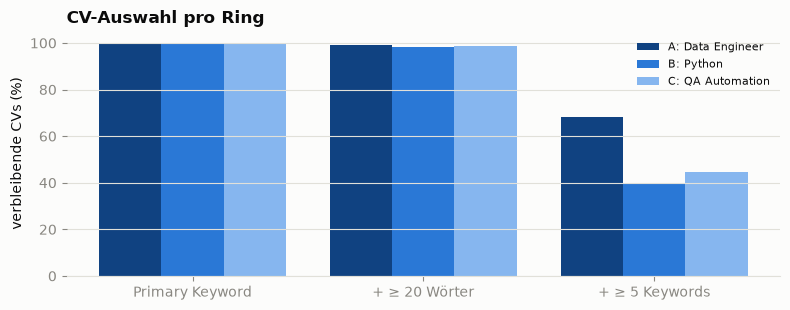

In [24]:
funnel_plot = pd.DataFrame(cv_funnel).T.iloc[:, :3]
remaining = funnel_plot.div(funnel_plot.iloc[:, 0], axis=0) * 100   # in % vom ersten Schritt

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(remaining.shape[1])
for i, (name, row) in enumerate(remaining.iterrows()):
    ax.bar(x + (i - 1) * 0.27, row.values, width=0.27, color=list(RING_COLORS.values())[i], label=name)
ax.set_xticks(x, remaining.columns)
ax.set_ylabel("verbleibende CVs (%)")
ax.set_title("CV-Auswahl pro Ring", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [25]:
print(cv_pools["A"][["Position", "n_keywords", "keywords_found"]].sample(5, random_state=SEED))
print(cv_pools["B"][["Position", "n_keywords", "keywords_found"]].sample(5, random_state=SEED))
print(cv_pools["C"][["Position", "n_keywords", "keywords_found"]].sample(5, random_state=SEED))

                                            Position  n_keywords  \
164006                          Senior Data Engineer           5   
23646                              Database Engineer          15   
24182   Data Engineer/Data Consultant/Data Architect           7   
23712                                  Data engineer           5   
161331                             SAP BI Consultant           6   

                                           keywords_found  
164006  [SQL, operate relational database management s...  
23646   [business intelligence, data warehouse, databa...  
24182   [business intelligence, database, SQL, data ex...  
23712   [MySQL, data extraction, transformation and lo...  
161331  [business intelligence, Java (computer program...  
                                  Position  n_keywords  \
139197                    Python Developer           6   
140148                    Python Developer           7   
142050             Python Middle Developer           5   

## 7. Markt ziehen

Aus den gefilterten Pools wird **zufällig** gezogen (Seed 42). Die Zwillings-Quellen sind andere CVs
als die Bewerberliste und werden reihum den 20 Jobs zugeordnet: 5 Haupttest-Paare + 1 Kontrolle pro Job.

In [26]:
market_jobs = job_pool.sample(N_JOBS, random_state=SEED).assign(doc_type="job", role="job", ring="A")

bewerberliste = pd.concat([
    cv_pools[key].sample(N_LIST, random_state=SEED).assign(role="liste", ring=key) for key in RINGS
])

twin_sources = pd.concat([
    cv_pools[key][~cv_pools[key]["id"].isin(bewerberliste["id"])].sample(n, random_state=SEED).assign(ring=key)
    for key, n in N_TWINS.items()
]).assign(role="zwilling_quelle")
twin_sources["test"] = np.where(twin_sources["ring"] == "C", "kontrolle", "haupttest")
twin_sources["assigned_job_id"] = [market_jobs["id"].iloc[i % N_JOBS] for i in range(len(twin_sources))]

market = pd.concat([market_jobs, bewerberliste.assign(doc_type="cv"), twin_sources.assign(doc_type="cv")],
                   ignore_index=True)
market.groupby(["role", "ring"]).size()

role             ring
job              A       20
liste            A       20
                 B       20
                 C       20
zwilling_quelle  A       70
                 B       30
                 C       20
dtype: int64

In [27]:
market_jobs[["Position", "Company Name", "Exp Years", "n_keywords"]]

,Position,Company Name,Exp Years,n_keywords
21293,Data engineer (Python),Data Science UA,1y,9
45239,Intern Data Engineer,Svitla Systems,no_exp,9
21303,Data Engineer (Python),Monster Lead Group,2y,14
9748,BI-ETL Developer,Storypoint,no_exp,11
53032,Junior Data Engineer (for Ukrainians who could...,VeraData,no_exp,15
29398,ETL Developer,Starnavi,3y,8
21132,Data Engineer -Dev Ops Specialist,DataFlik,3y,9
78175,Middle/Senior DWH Developer,Альфа-Банк Україна,2y,6
9925,Big Data Engineer,SoftServe,3y,16
21046,Data Engineer,N-iX,2y,14


## 8. Kontrolle (nur Bericht)

Ab hier wird nichts mehr ausgewählt. Wir prüfen den fertigen Markt mit beiden Methoden.

**ESCOX:** Wie viele ESCO-Labels findet ESCOX in den ausgewählten Texten? (Anforderung: ≥ 5)

In [28]:
extractor = EscoExtractor(EscoxConfig(esco_csv=ESCO_DIR / "skills_en.csv"))
escox_skills = market["text"].apply(extractor.extract)

market["esco_uris"] = escox_skills.apply(lambda found: [s.uri for s in found])
market["esco_labels"] = escox_skills.apply(lambda found: [s.label for s in found])
market["n_esco"] = market["esco_uris"].str.len()

market.groupby(["role", "ring"])["n_esco"].agg(
    median="median", minimum="min", anteil_ab_5=lambda n: (n >= 5).mean()).round(2)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

median  minimum  anteil_ab_5
role            ring                              
job             A       22.5       11         1.00
liste           A       16.5        7         1.00
                B       12.0        2         0.95
                C       14.0        3         0.95
zwilling_quelle A       13.0        3         0.94
                B        8.5        2         0.87
                C       22.0        6         1.00

**Spreizung:** Ranken beide Methoden die Liste von „passt“ (A) bis „passt kaum“ (C)?
MeritMe-Score = Recall (Anteil der Job-Labels im CV), Baseline = TF-IDF-Cosine auf denselben Texten.

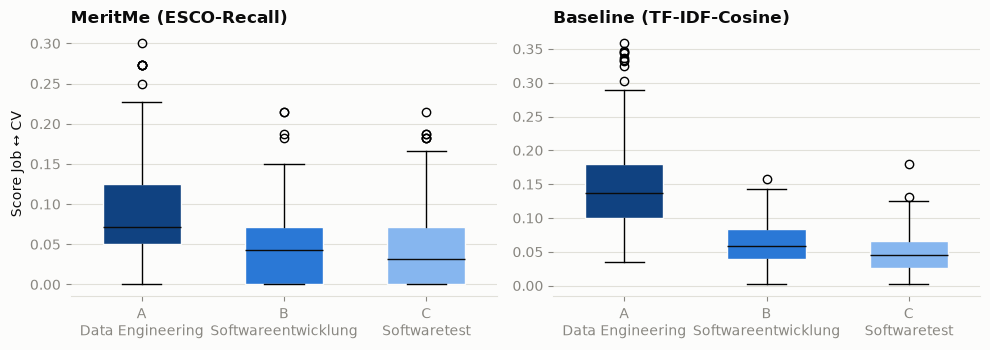

,MeritMe (ESCO-Recall),Baseline (TF-IDF-Cosine)
A: Data Engineering,0.071,0.137
B: Softwareentwicklung,0.043,0.059
C: Softwaretest,0.031,0.045


In [29]:
def esco_recall(job_uris: list, cv_uris: list) -> float:
    job_set = set(job_uris)
    return len(job_set & set(cv_uris)) / len(job_set) if job_set else 0.0


list_cvs = market[market["role"] == "liste"]
job_docs = market[market["role"] == "job"]

recall = np.array([[esco_recall(j, c) for c in list_cvs["esco_uris"]] for j in job_docs["esco_uris"]])
tfidf_market = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN).fit(market.loc[market["role"] != "zwilling_quelle", "text"])
cosine = cosine_similarity(tfidf_market.transform(job_docs["text"]), tfidf_market.transform(list_cvs["text"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (name, scores) in zip(axes, [("MeritMe (ESCO-Recall)", recall), ("Baseline (TF-IDF-Cosine)", cosine)]):
    data = [scores[:, (list_cvs["ring"] == key).to_numpy()].ravel() for key in RINGS]
    box = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={"color": INK})
    for patch, key in zip(box["boxes"], RINGS):
        patch.set_facecolor(RING_COLORS[key])
        patch.set_edgecolor(SURFACE)
    ax.set_xticks([1, 2, 3], [f"{k}\n{RINGS[k]['name']}" for k in RINGS])
    ax.set_title(name, loc="left", color=INK, fontweight="bold")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score Job ↔ CV")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "MeritMe (ESCO-Recall)": [np.median(recall[:, (list_cvs["ring"] == k).to_numpy()]) for k in RINGS],
    "Baseline (TF-IDF-Cosine)": [np.median(cosine[:, (list_cvs["ring"] == k).to_numpy()]) for k in RINGS],
}, index=[f"{k}: {RINGS[k]['name']}" for k in RINGS]).round(3)

In [30]:
distinct = np.mean([len(np.unique(row)) for row in recall])
print(f"Verschiedene Recall-Werte pro Job: Ø {distinct:.1f} von {len(list_cvs)} CVs (Gleichstände, siehe eda_keksausstecher)")

Verschiedene Recall-Werte pro Job: Ø 5.5 von 60 CVs (Gleichstände, siehe eda_keksausstecher)


## 9. Export

Eine Zeile pro Dokument. `keywords_found` zeigt, **warum** ein Dokument ausgewählt wurde;
`esco_labels` ist nur zur Kontrolle.

In [31]:
market = market.rename(columns={"Primary Keyword": "primary_keyword", "Position": "position"})
export = market[["id", "doc_type", "role", "ring", "test", "primary_keyword", "position", "assigned_job_id",
                 "n_words", "n_keywords", "keywords_found", "n_esco", "esco_uris", "esco_labels"]].assign(seed=SEED)

slug = RINGS["A"]["djinni_keyword"].lower().replace(" ", "-")
n_cvs = (export["doc_type"] == "cv").sum()
out_path = OUT_DIR / f"jobmarket_{slug}_{n_cvs}cv_{date.today()}.parquet"
export.to_parquet(out_path, index=False)

print(f"Gespeichert: {out_path} ({len(export)} Zeilen)")
export.head()

Gespeichert: ../data/processed/jobmarket_data-engineer_180cv_2026-10-20.parquet (200 Zeilen)


,id,doc_type,role,ring,test,primary_keyword,position,assigned_job_id,n_words,n_keywords,keywords_found,n_esco,esco_uris,esco_labels,seed
0,951f9b60-a6d9-59e7-8b98-4b74db572b81,job,job,A,NaN,Data Engineer,Data engineer (Python),NaN,290,9,"[information structure, JavaScript, SQL, data ...",32,[http://data.europa.eu/esco/skill/3cd569a2-4f8...,"[JavaScript, Python (computer programming), SQ...",42
1,4606c164-d4f8-563d-9b54-46e437a416ec,job,job,A,NaN,Data Engineer,Intern Data Engineer,NaN,153,9,"[business intelligence, data warehouse, SQL, d...",18,[http://data.europa.eu/esco/skill/598de5b0-5b5...,"[SQL, apply statistical analysis techniques, a...",42
2,31bff990-1eb3-5160-844a-05ec2d5ba843,job,job,A,NaN,Data Engineer,Data Engineer (Python),NaN,243,14,"[business intelligence, data warehouse, data e...",22,[http://data.europa.eu/esco/skill/ccd0a1d9-afd...,"[Python (computer programming), SPARK, aerospa...",42
3,0b04e287-8e84-594b-b448-98ab6725580f,job,job,A,NaN,Data Engineer,BI-ETL Developer,NaN,303,11,"[business intelligence, MDX, C#, SQL, SQL Serv...",16,[http://data.europa.eu/esco/skill/4c016b68-411...,"[C#, MDX, SQL, SQL Server Integration Services...",42
4,76f7039d-7de1-5f53-a77d-a94085d9ebaa,job,job,A,NaN,Data Engineer,Junior Data Engineer (for Ukrainians who could...,NaN,316,15,"[information structure, business intelligence,...",30,[http://data.europa.eu/esco/skill/6d3edede-895...,"[English, Hadoop, Microsoft Access, NoSQL, Ora...",42


## 10. Zusammenfassung

**Markt:** `jobmarket_data-engineer_180cv_2026-10-20.parquet` (Abschnitt 9) – 20 Jobs, Bewerberliste 20/20/20,
Zwillings-Quellen 70/30/20 (Abschnitt 7). Seed 42 nutzen alle EDA-Notebooks, die zufällig ziehen,
seit dem ersten EDA-Commit (13.09.2026) – er stand also vor der Marktauswahl fest. Ein erneuter Lauf liefert dieselben IDs.

**Ringe = ESCO-Berufsfamilien:** A Data Engineering, B Softwareentwicklung (Djinni: Python),
C Softwaretest (Djinni: QA Automation). A ist unser Fachgebiet und der IT-Fokus aus dem Antrag; dass ESCO
Data Engineering konkret beschreibt, ist die Voraussetzung für aussagekräftige Matched/Missing-Skills (Ziel 2).
Die B- und C-Paare testen MeritMe bewusst auch dort, wo ESCO schwächer ist – Stufe 1 deshalb pro Ring berichten.

**Auswahl ohne Score:**
- Nur englische Texte: CVs 196.757 von 210.250, Jobs 129.869 von 141.897 (Abschnitt 2)
- Jobs: 1.385 → Titel nennt Rolle 1.119 → ≥ 5 Keywords 1.020 → 20 zufällig (Abschnitte 5, 7)
- CVs: ≥ 5 Keywords der eigenen Ring-Liste bestehen 69 % (A), 41 % (B), 45 % (C) (Abschnitt 6)
- Keyword-Listen = ESCO-Sicht + TF-IDF-Sicht. Mit der ESCO-Sicht allein bestünden 51 % (A), 7 % (B), 5 % (C).
  Die TF-IDF-Begriffe werden automatisch aus den Top-30 je Ring übernommen (Abschnitt 4). Gestrichen wird nur,
  was die ESCO-Sicht des Rings schon abdeckt oder in `GENERIC_WORDS` steht (Konfiguration).
- Beide Methoden bekommen denselben Text; das Token-Muster erhält *c#*, *c++*, *.net*, damit die Baseline
  nicht geschwächt ist.

**Kontrolle (nur Bericht, Abschnitt 8):**
- ESCOX findet in 87–100 % der Texte je Gruppe mindestens 5 Labels.
- Beide Methoden ranken die Liste A > B > C (Median MeritMe 0,071 / 0,043 / 0,031, TF-IDF 0,137 / 0,059 / 0,045).
- MeritMe-Recall hat im Mittel nur 5,5 verschiedene Werte pro Job (Gleichstände) – Tie-Regel vor dem Ranking-Test festlegen.
- Die Kontrolle zeigt keinen Vorteil für MeritMe: TF-IDF trennt A deutlicher vom Rest, MeritMe ist grobkörniger.

**Abweichungen vom Plan:**
- Bewerberliste mit 60 statt 50 CVs, damit die drei Ringe gleich groß sind.
- Jobs aus Djinni statt EURES (Antrag): nur so tragen Jobs und CVs dasselbe `Primary Keyword`.
- Die 30 B-Paare werden für Data-Engineering-Stellen gerankt (Quereinstieg); die 20 C-Paare sind eine zusätzliche Kontrolle.

**Grenzen:**
- ESCO kennt viele Werkzeuge von B und C nicht.
- Der Keyword-Filter bevorzugt ausführlichere Texte – direkte Folge der Anforderung „≥ 5 extrahierbare Skills“.
- Der Kyrillisch-Filter entfernt auch Profile mit nur kyrillischem Titel. Vertretbar, weil MeritMe individuelle
  Fairness zwischen englischen Profilen prüft, nicht Gruppenfairness über Sprachen hinweg.
- Soft Skills sind bewusst kein Auswahlkriterium: sie unterscheiden die Ringe nicht und tragen den Schreibstil.
- Seniorität ist nicht kontrolliert.

**Nächster Schritt:** Markt einfrieren, erst danach Zwillinge erzeugen und Stufe 1 rechnen.

## 11. Aufbau der Parquet-Datei

Eine Zeile pro Dokument (20 Jobs + 180 CVs = 200 Zeilen).

| Spalte | Typ | Inhalt |
|---|---|---|
| `id` | str | Djinni-ID von CV oder Job, Schlüssel zu den Rohdaten |
| `doc_type` | str | `job` oder `cv` |
| `role` | str | `job`, `liste` (Bewerberliste) oder `zwilling_quelle` (Ausgangs-CV für ein Zwillingspaar) |
| `ring` | str | `A`, `B` oder `C` (Jobs immer `A`) |
| `test` | str | nur bei Zwillings-Quellen: `haupttest` (A, B) oder `kontrolle` (C), sonst leer |
| `primary_keyword` | str | Djinni-Keyword, der Ausstecher (`Data Engineer`, `Python`, `QA Automation`) |
| `position` | str | Titel aus Djinni, zum Lesen |
| `assigned_job_id` | str | nur bei Zwillings-Quellen: `id` des Jobs, für den das Paar gerankt wird, sonst leer |
| `n_words` | int | Wörter im Text (`Position + Highlights + Moreinfo` bzw. `Position + Long Description`) |
| `n_keywords` | int | Anzahl gefundener Keywords der eigenen Ring-Liste |
| `keywords_found` | list[str] | die gefundenen Keywords, also **warum** das Dokument ausgewählt wurde |
| `n_esco` | int | Anzahl der ESCOX-Labels (nur Kontrolle) |
| `esco_uris` | list[str] | ESCO-URIs der ESCOX-Labels (nur Kontrolle) |
| `esco_labels` | list[str] | Namen der ESCOX-Labels, gleiche Reihenfolge wie `esco_uris` (nur Kontrolle) |
| `seed` | int | Seed der Ziehung (42) |

Texte sind nicht gespeichert. Sie lassen sich über `id` aus `data/raw/djinni/` holen.